# Chapter 6 — Real-Time Bayesian Systems: Latency budgets and deadline misses

**Companion notebook for *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems*.**

**Credits.** Book author and scientific/editorial direction: **Khalid M. Mosalam** (UC Berkeley). Original companion notebook development: **Fan Hu**; additional notebooks and shared numerical implementations: **Ziad K. Mosalam**. This Chapter 6 numerical illustration extends the existing chapter calculation. Contributions and later refinements are documented in the repository README and Git history.

**Purpose.** Compare a deterministic sampling/latency budget with an explicitly **synthetic** sequence of timing measurements. This is a scheduling and queueing illustration, **not** field-measured processor performance or validation of a Bayesian estimator. The sample times refer to acquisition, while the queueing delay is modeled explicitly.

**Reproduce.** Execute the code cell to display and export the exact-array vector PDF and PNG figures under `figures/`. Panel (b) uses one marker per update exceeding the 4 ms deadline; all 14 missed updates are verified by assertions. Set the random seed or change the burst durations to test sensitivity.

## Case A — Sequential budget

Sampling rate: 200 Hz, so the sampling period is 5 ms. The example has sensing 0.8 ms, computation 2.5 ms, reporting 1.0 ms. These sum to 4.3 ms: a 4 ms end-to-end deadline is missed even though 4.3 ms is less than the 5 ms sampling period. Assume zero queueing delay.

## Case B — Burst and queueing

To study an **alternative optimized workload**, sensing remains 0.8 ms and reporting 1.0 ms, while computational times are mostly around 1.8 ms. Six deliberately slow computations create a queue. A single sequential worker handles computation and reporting; sensing is assumed independently completed 0.8 ms after acquisition. Samples arrive every 5 ms. End-to-end latency is completion time minus acquisition time. The deliberately injected delay burst is not claimed to be a statistical estimate of a deployed system.

Both cases use the same 4 ms deadline; the second case is an alternative scenario rather than another measurement of the first.

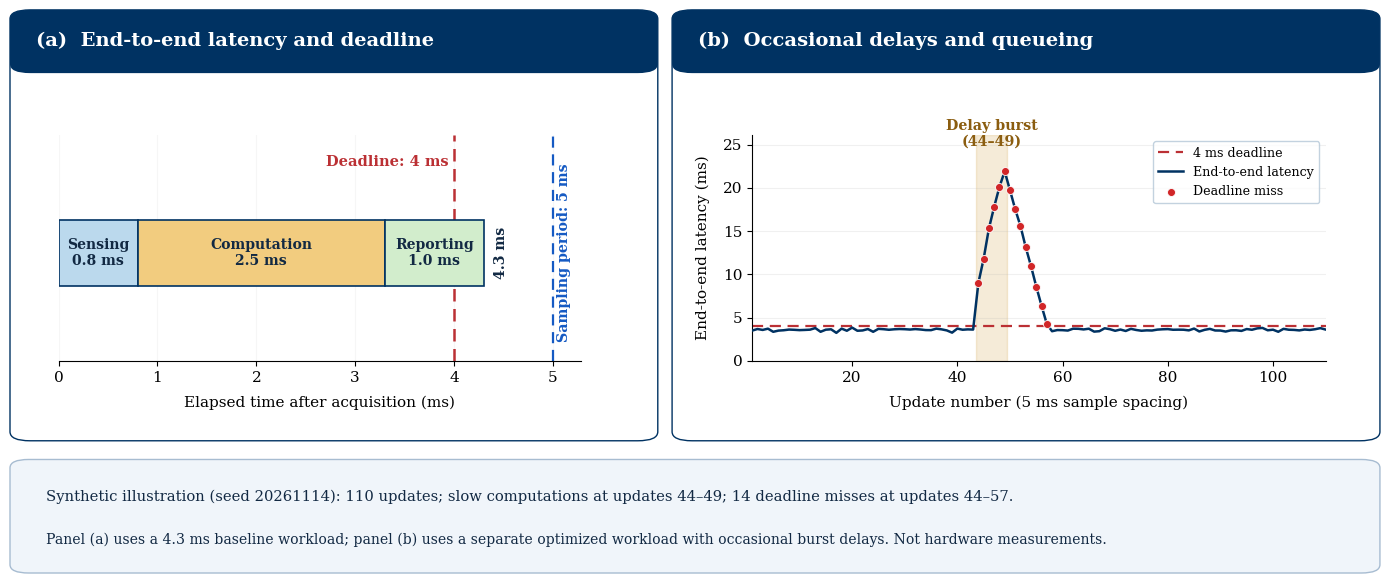

{'seed': 20261114, 'baseline_total_ms': 4.3, 'deadline_ms': 4.0, 'sample_period_ms': 5.0, 'updates': 110, 'slow_updates': [44, 45, 46, 47, 48, 49], 'missed_updates': [44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57], 'miss_count': 14, 'peak_latency_ms': 21.9, 'peak_update': 49}


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from pathlib import Path

# Chapter 6: All panel (b) ordinates and miss markers are generated from
# exactly the same latency array; no graphical approximation is used.
seed = 20261114
rng = np.random.default_rng(seed)
n = 110
sample_period_ms = 5.0
deadline_ms = 4.0
sensing_ms, reporting_ms = 0.8, 1.0
compute_ms = np.clip(rng.normal(1.8, 0.13, n), 1.43, 2.2)
compute_ms[43:49] = [7.2, 6.8, 7.5, 6.5, 6.3, 5.8]  # Updates 44..49 (1-based)
acquisition_ms = np.arange(n) * sample_period_ms
ready_ms = acquisition_ms + sensing_ms
completion_ms = np.zeros(n)
queue_ms = np.zeros(n)
for k in range(n):
    start_ms = max(ready_ms[k], completion_ms[k-1] if k else ready_ms[k])
    queue_ms[k] = start_ms - ready_ms[k]
    completion_ms[k] = start_ms + compute_ms[k] + reporting_ms
latency_ms = completion_ms - acquisition_ms
missed = latency_ms > deadline_ms
updates = np.arange(1, n + 1)  # Show 1-based update numbers in figure
missed_updates = updates[missed]
assert missed_updates.tolist() == list(range(44, 58))
assert len(missed_updates) == 14
assert np.isclose(latency_ms.max(), 21.9)
assert updates[np.argmax(latency_ms)] == 49

# Reproducible publication figure: both panels and notes in one vector export.
navy = '#003262'
blue = '#11507B'
gold = '#C9952B'
red = '#BB3034'
green = '#D2EDCC'
lightblue = '#BBD9ED'
palegold = '#F2CC7F'
ink = '#122943'
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.spines.top': False,
    'axes.spines.right': False})
fig = plt.figure(figsize=(14.3, 6.45), facecolor='white')
# Consistent panels, titles, caption strip (axes coordinates instead of data coordinates)
for x0, w, title in [(0.025,0.445,'(a)  End-to-end latency and deadline'),
                       (0.488,0.487,'(b)  Occasional delays and queueing')]:
    fig.add_artist(FancyBboxPatch((x0,0.285),w,0.66,boxstyle='round,pad=0.004,rounding_size=.014',
        transform=fig.transFigure,facecolor='white',edgecolor=navy,linewidth=1.0,zorder=0))
    fig.add_artist(FancyBboxPatch((x0,0.855),w,0.09,boxstyle='round,pad=0.004,rounding_size=.014',
        transform=fig.transFigure,facecolor=navy,edgecolor=navy,linewidth=0,zorder=0))
    fig.add_artist(Rectangle((x0,0.855),w,.046,transform=fig.transFigure,facecolor=navy,edgecolor='none',zorder=0))
    fig.text(x0+.014,0.901,title,color='white',fontsize=14.0,fontweight='bold',va='center')

# (a) x-axis is the actual elapsed time (ms)
a = fig.add_axes([.055,.405,.365,.35],zorder=3)
a.set_xlim(0,5.28);a.set_ylim(-.52,.57)
segments=[(0,.8,'Sensing\n0.8 ms',lightblue),(.8,2.5,'Computation\n2.5 ms',palegold),
          (3.3,1.0,'Reporting\n1.0 ms',green)]
for start,width,title,c in segments:
    a.add_patch(Rectangle((start,-.16),width,.32,facecolor=c,edgecolor=navy,linewidth=1.2,zorder=3))
    a.text(start+width/2,0,title.replace('\\n','\n'),ha='center',va='center',fontsize=10.1,
           color=ink,fontweight='bold',zorder=5)
# One continuous 4-ms vertical reference, no offset in any section.
a.axvline(4,color=red,ls=(0,(5,3)),lw=1.8,zorder=2)
a.text(3.95,.42,'Deadline: 4 ms',color=red,ha='right',fontsize=10.5,fontweight='bold')
a.axvline(5,color='#155AC3',ls=(0,(5,3)),lw=1.6,zorder=2)
a.text(5.11,0,'Sampling period: 5 ms',rotation=90,ha='center',va='center',
       color='#155AC3',fontweight='bold',fontsize=10.2)
# Outside the right edge of the green bar, same vertical orientation.
a.text(4.40,0,'4.3 ms',rotation=90,va='center',ha='left',fontweight='bold',fontsize=10.2,color=ink)
a.set_xticks(range(6));a.set_yticks([])
a.set_xlabel('Elapsed time after acquisition (ms)',labelpad=8,fontsize=11)
a.spines[['left']].set_visible(False)
a.grid(axis='x',alpha=.11,zorder=0)

# (b) plot the true notebook arrays, including all 14 red dots.
b = fig.add_axes([.54,.405,.401,.35],zorder=3)
b.axvspan(43.5,49.5,color=gold,alpha=.18,zorder=0)
b.axhline(deadline_ms,color=red,ls=(0,(5,3)),lw=1.6,label='4 ms deadline',zorder=2)
b.plot(updates,latency_ms,color=navy,lw=1.8,label='End-to-end latency',zorder=3)
b.scatter(missed_updates,latency_ms[missed],s=33,color='#D12628',edgecolors='white',
          linewidth=.6,label='Deadline miss',zorder=5)
b.annotate('Delay burst\n(44–49)',xy=(46.5,22.0),xytext=(46.5,24.5),
           ha='center',va='bottom',fontsize=10.3,fontweight='bold',color='#8B5D10',
           arrowprops=dict(arrowstyle='-',lw=0),zorder=6)
b.set_xlim(1,110);b.set_ylim(0,26.1)
b.set_xticks([20,40,60,80,100]);b.set_yticks([0,5,10,15,20,25])
b.set_xlabel('Update number (5 ms sample spacing)',labelpad=8,fontsize=11)
b.set_ylabel('End-to-end latency (ms)',fontsize=11,labelpad=9)
b.grid(axis='y',alpha=.18,zorder=0)
b.legend(loc='upper right',fontsize=9.1,frameon=True,facecolor='white',edgecolor='#B4C7D7',ncol=1)

# Bottom notes touch the panel group without excess whitespace.
fig.add_artist(FancyBboxPatch((.025,.08),.95,.168,boxstyle='round,pad=0.004,rounding_size=.013',
                              facecolor='#F0F5FA',edgecolor='#A7BCD1',linewidth=1,transform=fig.transFigure,zorder=0))
fig.text(.046,.194,'Synthetic illustration (seed 20261114): 110 updates; slow computations 44–49; 14 deadline misses 44–57.',
         fontsize=14.0,color=ink,va='center')
fig.text(.046,.128,'Panel (a): 4.3 ms baseline workload. Panel (b): optimized workload with burst delays. Synthetic, not hardware measurements.',
         fontsize=14,color=ink,va='center')

out = Path('figures');out.mkdir(exist_ok=True)
fig.savefig(out/'JNB6-realtime-latency-final.pdf',bbox_inches='tight',facecolor='white')
fig.savefig(out/'JNB6-realtime-latency-final.png',dpi=190,bbox_inches='tight',facecolor='white')
plt.show()
print({'seed':seed,'baseline_total_ms':4.3,'deadline_ms':deadline_ms,
       'sample_period_ms':sample_period_ms,'updates':n,
       'slow_updates':list(range(44,50)),
       'missed_updates':missed_updates.tolist(), 'miss_count':int(missed.sum()),
       'peak_latency_ms':round(float(latency_ms.max()),4),
       'peak_update':int(updates[latency_ms.argmax()])})


## Interpretation

The first panel compares a 4.3 ms end-to-end latency against a stricter 4 ms deadline and a 5 ms sampling period. The second panel plots the computed completion times of a separate optimized sequential workload. The injected six-update burst occurs at 1-based updates 44–49; queueing keeps latency above the 4 ms deadline through update 57, yielding exactly 14 misses. The maximum is 21.9 ms at update 49. The red markers are generated directly from the Boolean array `latency_ms > deadline_ms`, not manually drawn. These results are synthetic and do not constitute measured hardware performance.
